# Fresh produce shortage early warning

**Problem.** Fresh produce availability swings with the seasons, the weather, fuel costs and supply disruptions. Weather affects supply with a delay of a month or two, so it should give some advance notice of trouble.

**Task.** At the end of month *t*, predict whether a given product at a given store will have a **shortage** (`availability_pct < 82`, flagged as `shortage_flag = 1`) in month *t+h*, for *h* = 1, 2 and 3 months. About 9% of rows are shortages, so the classes are imbalanced and accuracy is not a useful metric. The main metric is **PR-AUC** (average precision), where a model with no skill scores about 0.08.

**The data is simulated** (see `generate_produce_data.py`). Conclusions are about the method, not the real produce market.

**Contents**
1. Data preparation and cleaning
2. Exploratory data analysis
3. Features, targets and the time-based split
4. Feature importance analysis
5. Model selection
6. Hyperparameter tuning (time-ordered cross-validation)
7. Final evaluation on the untouched test years

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, mutual_info_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import ParameterSampler

import produce_features as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

DATA = "data/synthetic_produce_prices_1990_2025.csv"
HORIZONS = list(pf.HORIZONS)

## 1. Data preparation and cleaning

One row is one product at one store in one month. We check types, missing values, duplicates, impossible values and internal consistency before using anything.

In [2]:
raw = pd.read_csv(DATA)
print(raw.shape)
display(raw.head(3))
display(raw.dtypes.to_frame("dtype").T)

(10000, 25)


,record_id,date,year,month,store_id,store_name,region,store_tier,product,unit,avg_temp_c,temp_anomaly_c,precip_mm,drought_index,frost_days,heatwave_days,enso_index,cpi_index,fuel_cost_index,import_disruption_index,promotion_flag,covid_period,price_usd_per_lb,availability_pct,shortage_flag
0,1,1990-01-01,1990,1,S01,FreshMart Northeast,Northeast,premium,apples,lb,-3.9,-1.9,87.6,0.0,7,0,-0.04,100.0,101.2,-0.69,1,0,0.72,95.0,0
1,2,1990-01-01,1990,1,S01,FreshMart Northeast,Northeast,premium,avocados,lb,-3.9,-1.9,87.6,0.0,7,0,-0.04,100.0,101.2,-0.69,0,0,1.77,82.9,0
2,3,1990-01-01,1990,1,S01,FreshMart Northeast,Northeast,premium,bananas,lb,-3.9,-1.9,87.6,0.0,7,0,-0.04,100.0,101.2,-0.69,0,0,0.43,94.4,0


,record_id,date,year,month,store_id,store_name,region,store_tier,product,unit,avg_temp_c,temp_anomaly_c,precip_mm,drought_index,frost_days,heatwave_days,enso_index,cpi_index,fuel_cost_index,import_disruption_index,promotion_flag,covid_period,price_usd_per_lb,availability_pct,shortage_flag
dtype,int64,str,int64,int64,str,str,str,str,str,str,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,int64,int64,float64,float64,int64


In [3]:
df = raw.copy()
df["date"] = pd.to_datetime(df["date"])

checks = pd.Series({
    "missing cells": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "duplicate (date, store, product)": int(df.duplicated(["date", "store_id", "product"]).sum()),
    "non-positive prices": int((df["price_usd_per_lb"] <= 0).sum()),
    "availability outside 0-100": int((~df["availability_pct"].between(0, 100)).sum()),
    "dates not on the 1st of a month": int((df["date"].dt.day != 1).sum()),
    "shortage_flag disagrees with availability < 82": int(((df["availability_pct"] < 82).astype(int) != df["shortage_flag"]).sum()),
    "frost/heat days outside 0-31": int((~df["frost_days"].between(0, 31) | ~df["heatwave_days"].between(0, 31)).sum()),
})
display(checks.to_frame("count"))
assert (checks == 0).all()

,count
missing cells,0
duplicate rows,0
"duplicate (date, store, product)",0
non-positive prices,0
availability outside 0-100,0
dates not on the 1st of a month,0
shortage_flag disagrees with availability < 82,0
frost/heat days outside 0-31,0


In [4]:
display(df.describe().T[["min", "25%", "50%", "75%", "max"]].round(2))
for c in ["store_id", "region", "store_tier", "product", "unit"]:
    print(c, "->", sorted(df[c].unique()))

,min,25%,50%,75%,max
record_id,1.0,2500.75,5000.5,7500.25,10000.0
date,1990-01-01 00:00:00,1999-01-01 00:00:00,2007-12-16 12:00:00,2017-01-01 00:00:00,2025-12-01 00:00:00
year,1990.0,1999.0,2007.5,2017.0,2025.0
month,1.0,3.0,6.0,9.0,12.0
avg_temp_c,-6.4,8.9,15.0,21.1,31.7
temp_anomaly_c,-4.41,-0.57,0.49,1.49,5.59
precip_mm,6.9,51.0,78.35,109.6,308.3
drought_index,-4.72,-1.64,-0.68,0.34,3.98
frost_days,0.0,0.0,0.0,2.0,19.0
heatwave_days,0.0,0.0,0.0,0.0,17.0


store_id -> ['S01', 'S02', 'S03', 'S04']
region -> ['Midwest', 'Northeast', 'South', 'West']
store_tier -> ['discount', 'mainstream', 'premium']
product -> ['apples', 'avocados', 'bananas', 'broccoli', 'carrots', 'grapes', 'lettuce', 'onions', 'oranges', 'potatoes', 'strawberries', 'tomatoes']
unit -> ['lb']


In [5]:
# Months with no price report: each store-product series should have one row per month.
months = pd.date_range(df["date"].min(), df["date"].max(), freq="MS")
per_series = df.groupby(["store_id", "product"]).size()
print(f"{len(months)} months, {len(per_series)} series; rows per series: min {per_series.min()}, max {per_series.max()}")
print(f"overall share of months with no report: {1 - len(df) / (len(months) * len(per_series)):.1%}")

# Longest run of consecutive missing months in any series
longest = 0
for _, g in df.groupby(["store_id", "product"]):
    idx = months.get_indexer(g["date"])
    gaps = np.diff(np.concatenate([[-1], idx, [len(months)]])) - 1
    longest = max(longest, gaps.max())
print("longest run of consecutive missing months in any series:", longest)

432 months, 24 series; rows per series: min 412, max 427
overall share of months with no report: 3.5%
longest run of consecutive missing months in any series: 3


**Cleaning conclusions.** There are no missing values, duplicates or impossible values, and the flag matches availability exactly. The only issue is about 3.5% of store-product-months with no report (random gaps). We do not fill those in. Instead, features and targets are built on a complete monthly calendar (section 3), so every lag is taken by date and a missing month simply produces a blank feature (which gradient boosting handles natively) rather than silently shifting the data.

## 2. Exploratory data analysis

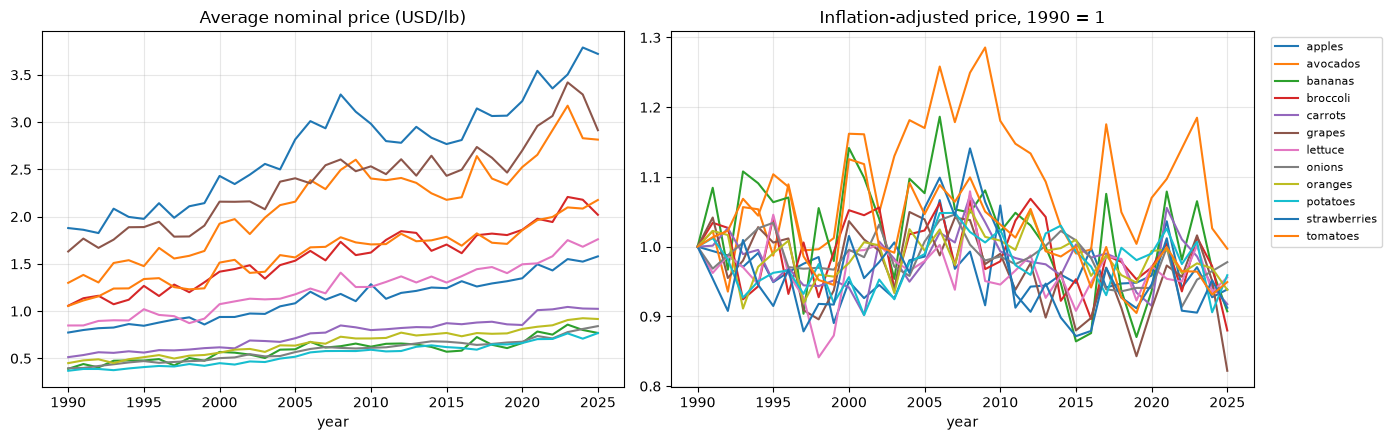

In [6]:
# Prices over time: nominal, and with inflation removed
df["real_price"] = np.exp(pf.real_log_price(df["price_usd_per_lb"], df["cpi_index"]))
nominal = df.groupby(["year", "product"])["price_usd_per_lb"].mean().unstack()
real = df.groupby(["year", "product"])["real_price"].mean().unstack()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
nominal.plot(ax=ax[0], legend=False)
ax[0].set_title("Average nominal price (USD/lb)")
(real / real.iloc[0]).plot(ax=ax[1])
ax[1].set_title("Inflation-adjusted price, 1990 = 1")
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

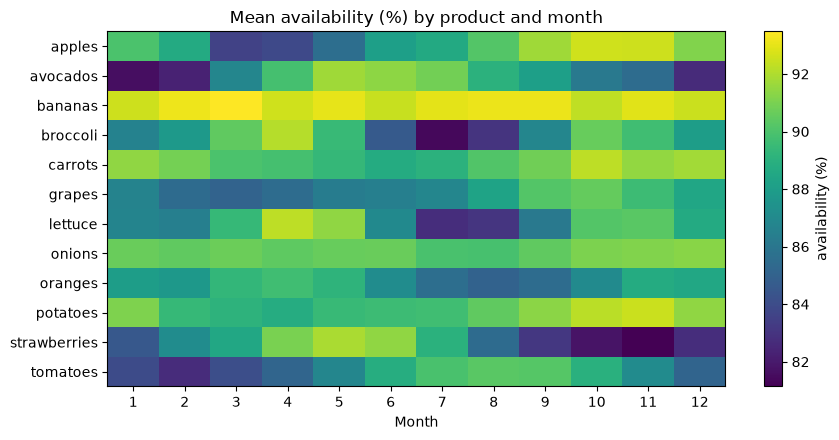

In [7]:
# Seasonality of availability by product
seasonal = df.groupby(["product", "month"])["availability_pct"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(seasonal.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(seasonal)))
ax.set_yticklabels(seasonal.index)
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
ax.set_xlabel("Month")
ax.set_title("Mean availability (%) by product and month")
ax.grid(False)
plt.colorbar(im, label="availability (%)")
plt.tight_layout()
plt.show()

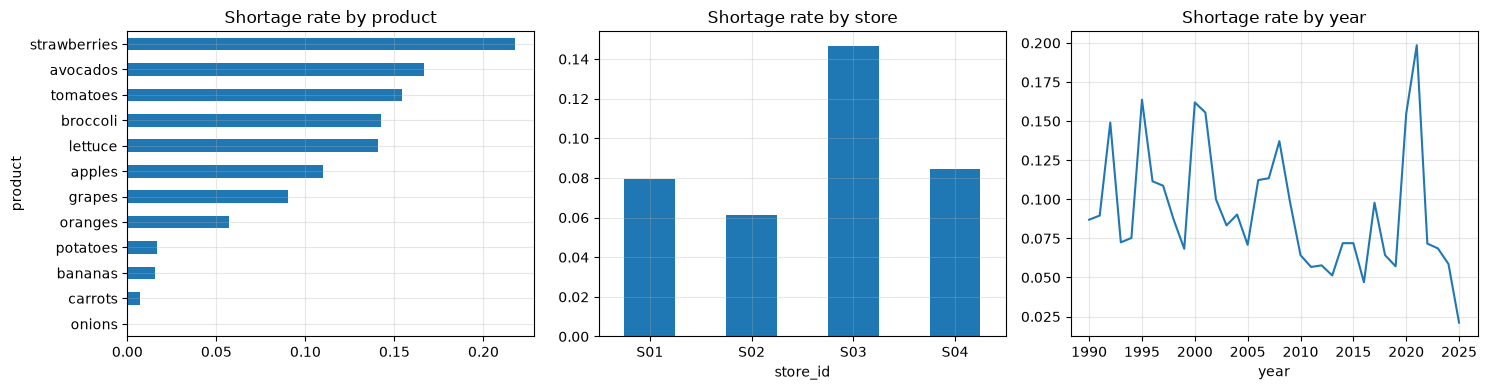

overall shortage rate: 9.3%


In [8]:
# Where do shortages happen?
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("product")["shortage_flag"].mean().sort_values().plot.barh(ax=ax[0], title="Shortage rate by product")
df.groupby("store_id")["shortage_flag"].mean().plot.bar(ax=ax[1], title="Shortage rate by store", rot=0)
df.groupby("year")["shortage_flag"].mean().plot(ax=ax[2], title="Shortage rate by year")
plt.tight_layout()
plt.show()
print(f"overall shortage rate: {df['shortage_flag'].mean():.1%}")

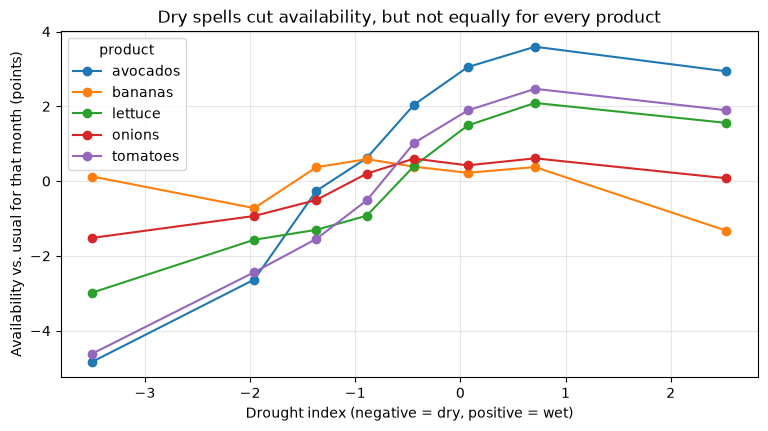

,drought_index,temp_anomaly_c,frost_days,heatwave_days,precip_mm
apples,0.35,-0.26,-0.01,-0.11,0.03
avocados,0.66,-0.23,-0.03,-0.13,0.11
bananas,-0.05,-0.02,-0.01,-0.01,-0.03
broccoli,0.34,-0.50,0.05,-0.21,0.05
carrots,0.42,-0.26,0.01,-0.11,0.04
grapes,0.30,-0.36,0.04,-0.14,0.03
lettuce,0.41,-0.54,-0.00,-0.18,0.07
onions,0.17,-0.13,-0.02,-0.06,-0.01
oranges,0.40,-0.19,-0.01,-0.08,0.06
potatoes,0.39,-0.18,0.00,-0.07,-0.02


In [9]:
# Weather effect on availability, after removing the usual seasonal pattern
d = df.copy()
d["avail_resid"] = d["availability_pct"] - d.groupby(["store_id", "product", "month"])["availability_pct"].transform("mean")

d["drought_bin"] = pd.qcut(d["drought_index"], 8)
sel = ["tomatoes", "avocados", "lettuce", "bananas", "onions"]
tab = d[d["product"].isin(sel)].groupby(["drought_bin", "product"], observed=True)["avail_resid"].mean().unstack()
tab.index = [round(iv.mid, 2) for iv in tab.index]
tab.plot(marker="o")
plt.xlabel("Drought index (negative = dry, positive = wet)")
plt.ylabel("Availability vs. usual for that month (points)")
plt.title("Dry spells cut availability, but not equally for every product")
plt.show()

wcols = ["drought_index", "temp_anomaly_c", "frost_days", "heatwave_days", "precip_mm"]
corr = pd.DataFrame({p: g[wcols].corrwith(g["avail_resid"]) for p, g in d.groupby("product")}).T
display(corr.round(2))

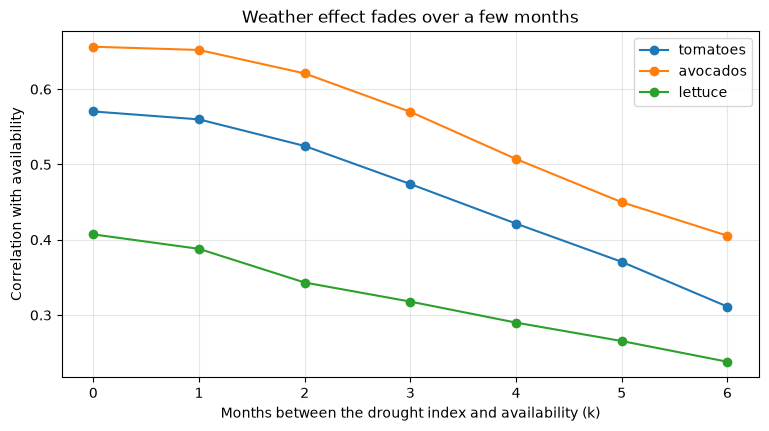

In [10]:
# How long does weather take to show up in availability?
# Correlate availability with the drought index k months EARLIER (matched by date).
res = {}
for prod in ["tomatoes", "avocados", "lettuce"]:
    dp = d[d["product"] == prod]
    vals = []
    for k in range(0, 7):
        lagged = dp[["store_id", "date", "drought_index"]].copy()
        lagged["date"] = lagged["date"] + pd.DateOffset(months=k)
        m = dp.merge(lagged, on=["store_id", "date"], suffixes=("", "_lag"))
        vals.append(m["avail_resid"].corr(m["drought_index_lag"]))
    res[prod] = vals
pd.DataFrame(res, index=range(0, 7)).plot(marker="o")
plt.xlabel("Months between the drought index and availability (k)")
plt.ylabel("Correlation with availability")
plt.title("Weather effect fades over a few months")
plt.show()

**EDA takeaways** (see the charts above)

- Prices rise with inflation and swing seasonally. Availability dips off-season for the seasonal crops and is flat for bananas.
- Shortages are concentrated in a few products: strawberries (about 22% of months), avocados, tomatoes, broccoli and lettuce (14-17%). They are rare for potatoes, bananas, carrots and absent for onions. The South store (S03) has the most shortages, about 15% of months.
- The shortage rate is **not** constant over time. It ranges from about 2% to 20% per year, drifts down as logistics improve, and spikes around 2000 and in 2020-2021 (the covid period). The test years (2021-2025) contain that spike followed by very calm years, which matters when judging the final results.
- Dry conditions reduce availability, and products differ in how much: strongest for avocados and tomatoes, almost none for bananas. Hot weather and warm anomalies hurt lettuce, broccoli and strawberries most.
- The correlation between the drought index and availability is highest for weather in the same or previous month and declines gradually over six months. Part of that slow fade is simply that the drought index itself changes slowly. It supports using current and recent weather to look 1-3 months ahead, and suggests the warning weakens as the horizon grows.

## 3. Features, targets and the time-based split

For every store-product series we build a table on a complete monthly calendar. For each month *t* and horizon *h*:

- **Target:** `y` = shortage flag in month *t+h*.
- **Features, all known at month *t*:** availability now and 1, 2, 3, 12 months ago; inflation-adjusted price now and 1, 12 months ago; fuel cost; regional weather (current value and 3-month average of drought index, frost days, heat days, temperature anomaly) and ENSO index; the calendar month being predicted (as sine/cosine); store and product.
- **Split by the month being predicted:** train 1991-2015, validation 2016-2020, test 2021-2025. The test years are not touched until section 7.

The same code (`produce_features.py`) is used by `train.py` and the web service, so features are identical in experiments and serving.

In [11]:
panel = pf.build_panel(df)
print(panel.shape, "rows (24 series x 432 months)")
cols = ["t", "avail", "avail_lag1", "avail_lag2", "avail_lag12", "real_logprice", "drought_index", "drought_index_3m", "y_h1", "y_h3"]
display(panel[(panel.store_id == "S01") & (panel["product"] == "strawberries")][cols].iloc[24:30].round(2))

(10368, 29) rows (24 series x 432 months)


,t,avail,avail_lag1,avail_lag2,avail_lag12,real_logprice,drought_index,drought_index_3m,y_h1,y_h3
1752,1992-01-01,83.1,84.0,83.7,88.3,0.74,-1.05,-0.77,0.0,0.0
1753,1992-02-01,88.3,83.1,84.0,91.0,0.54,-1.23,-1.03,0.0,0.0
1754,1992-03-01,92.3,88.3,83.1,90.5,0.49,-0.61,-0.96,0.0,0.0
1755,1992-04-01,93.0,92.3,88.3,96.9,0.42,0.06,-0.59,0.0,0.0
1756,1992-05-01,98.2,93.0,92.3,95.3,0.35,1.09,0.18,0.0,0.0
1757,1992-06-01,97.3,98.2,93.0,95.6,0.38,2.30,1.15,0.0,0.0


In [12]:
frames = {h: pf.horizon_frame(panel, h) for h in HORIZONS}

rows = []
for h in HORIZONS:
    tr, va, te = pf.split_by_target_year(frames[h])
    rows.append({"horizon": h, "train": len(tr), "val": len(va), "test": len(te),
                 "shortage rate train": round(tr.y.mean(), 3),
                 "shortage rate val": round(va.y.mean(), 3), "shortage rate test": round(te.y.mean(), 3)})
display(pd.DataFrame(rows).set_index("horizon"))

,train,val,test,shortage rate train,shortage rate val,shortage rate test
horizon,,,,,,
1,7196,1391,1390,0.097,0.084,0.083
2,7172,1391,1390,0.097,0.084,0.083
3,7148,1391,1390,0.097,0.084,0.083


## 4. Feature importance analysis

Two views, both using the training years (and the validation years for model-based importance), never the test years:

1. **Mutual information** between each feature and the target: model-free, shows which features carry any signal.
2. **Permutation importance** of a boosting model: how much validation PR-AUC drops when a feature (or a whole group of features) is shuffled.

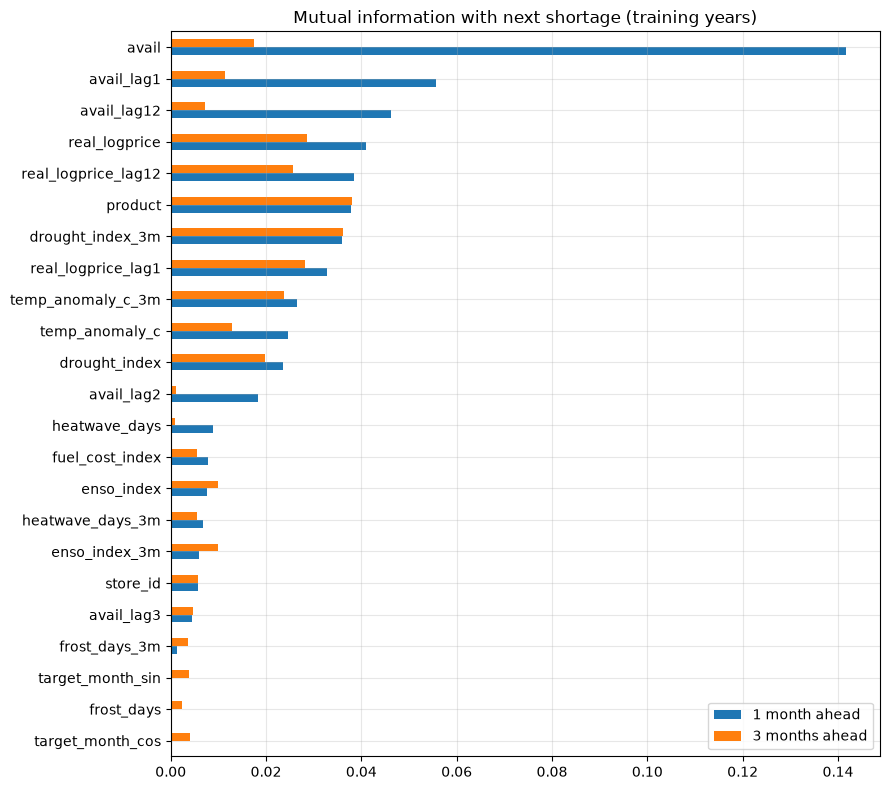

In [13]:
feats = pf.FEATURES
tr1, va1, te1 = pf.split_by_target_year(frames[1])
tr3, va3, te3 = pf.split_by_target_year(frames[3])

def mutual_info_table(tr):
    X = tr[pf.ALL_NUM].fillna(tr[pf.ALL_NUM].median())
    mi = pd.Series(mutual_info_classif(X, tr["y"], random_state=1), index=pf.ALL_NUM)
    for c in pf.CATEGORICAL:
        mi[c] = mutual_info_score(tr[c], tr["y"])
    return mi

mi = pd.DataFrame({"1 month ahead": mutual_info_table(tr1), "3 months ahead": mutual_info_table(tr3)})
mi = mi.sort_values("1 month ahead", ascending=True)
mi.plot.barh(figsize=(9, 8), title="Mutual information with next shortage (training years)")
plt.tight_layout()
plt.show()

1 month(s) ahead:
availability (now and past)    0.459
inflation-adjusted price       0.082
store and product              0.072
month being predicted          0.057
weather and ENSO               0.041
fuel cost                      0.008



3 month(s) ahead:
store and product              0.201
inflation-adjusted price       0.166
month being predicted          0.096
weather and ENSO               0.071
availability (now and past)    0.033
fuel cost                      0.025



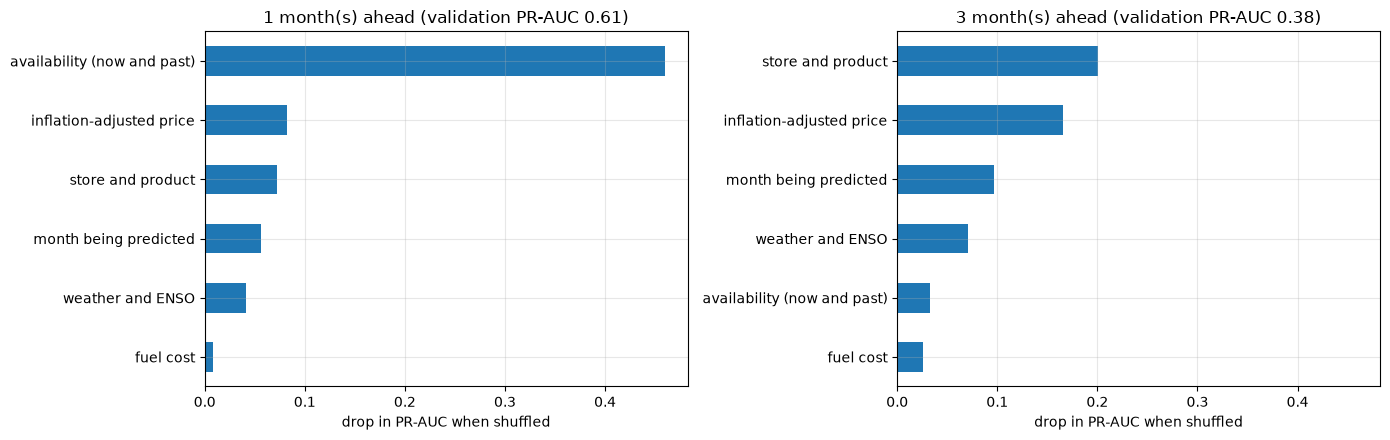

In [14]:
def permutation_by_group(model, X, y, groups, n_repeats=5, seed=1):
    """Drop in PR-AUC when a group of columns is shuffled together."""
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out[name] = float(np.mean(drops))
    return pd.Series(out).sort_values(ascending=False), base

single = {c: [c] for c in feats}
groups = {
    "availability (now and past)": ["avail", "avail_lag1", "avail_lag2", "avail_lag3", "avail_lag12"],
    "inflation-adjusted price": ["real_logprice", "real_logprice_lag1", "real_logprice_lag12"],
    "weather and ENSO": pf.WEATHER_NUM,
    "month being predicted": ["target_month_sin", "target_month_cos"],
    "fuel cost": ["fuel_cost_index"],
    "store and product": pf.CATEGORICAL,
}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for a, (h, tr, va) in zip(ax, [(1, tr1, va1), (3, tr3, va3)]):
    m = pf.make_model("boosting", pf.ALL_NUM).fit(tr[feats], tr["y"])
    g, base = permutation_by_group(m, va[feats], va["y"], groups)
    g.iloc[::-1].plot.barh(ax=a, title=f"{h} month(s) ahead (validation PR-AUC {base:.2f})")
    a.set_xlabel("drop in PR-AUC when shuffled")
    print(f"{h} month(s) ahead:"); print(g.round(3).to_string()); print()
plt.tight_layout()
plt.show()

In [15]:
# The same, one feature at a time (1 and 3 months ahead)
top = {}
for h, tr, va in [(1, tr1, va1), (3, tr3, va3)]:
    m = pf.make_model("boosting", pf.ALL_NUM).fit(tr[feats], tr["y"])
    s, _ = permutation_by_group(m, va[feats], va["y"], single)
    top[f"{h} month(s) ahead"] = s
top = pd.DataFrame(top).sort_values("1 month(s) ahead", ascending=False)
display(top.head(12).round(4))

,1 month(s) ahead,3 month(s) ahead
avail,0.4496,0.0124
product,0.0451,0.0875
target_month_sin,0.0437,0.0477
store_id,0.0392,0.1405
real_logprice_lag12,0.0313,0.0356
temp_anomaly_c,0.0187,0.0082
real_logprice,0.0179,0.0390
drought_index,0.0158,0.0023
avail_lag2,0.0155,-0.0012
real_logprice_lag1,0.0152,0.0396


**Importance takeaways**

- **One month ahead,** current and recent availability dominates by a wide margin: shuffling it cuts validation PR-AUC by about 0.46, far more than any other group. The simplest predictor of next month's shortage is whether things are already tight.
- **Three months ahead,** availability matters much less (about 0.03). Store and product (some items simply run short more often), inflation-adjusted price, the calendar month and weather take over. Weather's contribution grows from about 0.04 to about 0.07 as the horizon lengthens, which fits the idea that weather is more useful for looking further ahead.
- Inflation-adjusted price is useful at both horizons. In this data, price and availability both react to the same supply stress, so price acts as a second signal of trouble.
- Fuel cost adds little.
- Mutual information (model-free) shows the same picture: availability first at 1 month, store/product and seasonality at 3 months.

## 5. Model selection

We compare simple baselines with three model families, each with and without the weather features, trained on the training years and scored on the **validation** years. The test years stay untouched. The headline metric is PR-AUC averaged over the three horizons.

Baselines: *never shortage*; *persistence* (shortage next period if shortage now); *same month last year*.

,1 month(s),2 month(s),3 month(s),mean
random forest (no weather),0.566,0.417,0.425,0.469
gradient boosting (+ weather),0.611,0.395,0.377,0.461
gradient boosting (no weather),0.587,0.398,0.373,0.453
random forest (+ weather),0.556,0.399,0.394,0.450
logistic regression (+ weather),0.598,0.363,0.286,0.415
logistic regression (no weather),0.547,0.299,0.240,0.362
baseline: persistence,0.268,0.132,0.095,0.165
baseline: same month last year,0.158,0.158,0.158,0.158
baseline: never shortage,0.084,0.084,0.084,0.084


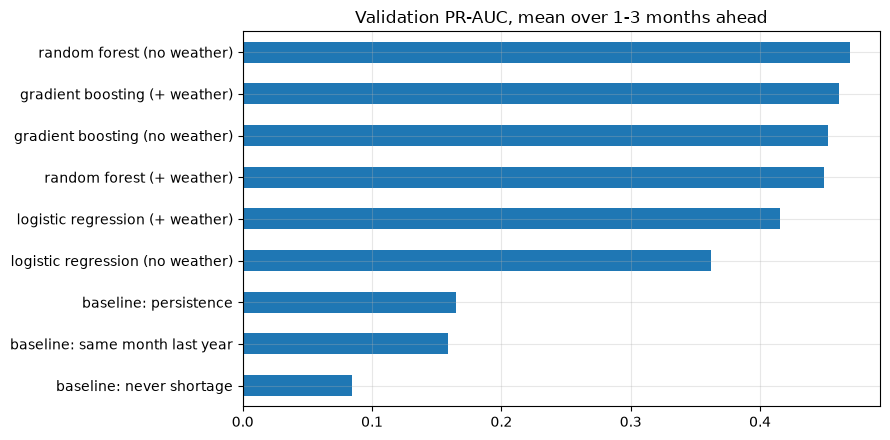

In [16]:
def val_pr_auc(kind, num_cols, params=None):
    scores = []
    for h in HORIZONS:
        tr, va, _ = pf.split_by_target_year(frames[h])
        cols = num_cols + pf.CATEGORICAL
        m = pf.make_model(kind, num_cols, params).fit(tr[cols], tr["y"])
        scores.append(average_precision_score(va["y"], m.predict_proba(va[cols])[:, 1]))
    return scores

candidates = {
    "logistic regression (no weather)": ("logistic", pf.BASE_NUM),
    "logistic regression (+ weather)": ("logistic", pf.ALL_NUM),
    "random forest (no weather)": ("forest", pf.BASE_NUM),
    "random forest (+ weather)": ("forest", pf.ALL_NUM),
    "gradient boosting (no weather)": ("boosting", pf.BASE_NUM),
    "gradient boosting (+ weather)": ("boosting", pf.ALL_NUM),
}

rows = {}
for name, (kind, cols) in candidates.items():
    rows[name] = val_pr_auc(kind, cols)

base_rows = {"baseline: never shortage": [], "baseline: persistence": [], "baseline: same month last year": []}
for h in HORIZONS:
    _, va, _ = pf.split_by_target_year(frames[h])
    base_rows["baseline: never shortage"].append(average_precision_score(va["y"], np.zeros(len(va))))
    base_rows["baseline: persistence"].append(average_precision_score(va["y"], va["persist"]))
    base_rows["baseline: same month last year"].append(average_precision_score(va["y"], va["seasonal"]))
rows.update(base_rows)

sel = pd.DataFrame(rows, index=[f"{h} month(s)" for h in HORIZONS]).T
sel["mean"] = sel.mean(axis=1)
sel = sel.sort_values("mean", ascending=False)
display(sel.round(3))

sel["mean"].iloc[::-1].plot.barh(figsize=(9, 4.5), title="Validation PR-AUC, mean over 1-3 months ahead")
plt.tight_layout()
plt.show()

In [17]:
# Does adding weather help, for each family?
for fam in ["logistic regression", "random forest", "gradient boosting"]:
    gain = sel.loc[f"{fam} (+ weather)", sel.columns[:3]] - sel.loc[f"{fam} (no weather)", sel.columns[:3]]
    print(f"{fam:20s} PR-AUC gain from weather:", gain.round(3).to_dict())

logistic regression  PR-AUC gain from weather: {'1 month(s)': 0.051, '2 month(s)': 0.064, '3 month(s)': 0.046}
random forest        PR-AUC gain from weather: {'1 month(s)': -0.009, '2 month(s)': -0.018, '3 month(s)': -0.031}
gradient boosting    PR-AUC gain from weather: {'1 month(s)': 0.024, '2 month(s)': -0.003, '3 month(s)': 0.004}


**What the validation table says**

- Every model family beats all three baselines by a wide margin (0.36 to 0.47 average PR-AUC against 0.17 for persistence).
- The top three are close: random forest without weather (0.469), boosting with weather (0.461) and boosting without weather (0.453). Gaps of this size are within noise for a validation set with about 115 shortages. Boosting with weather is best at 1 month ahead (0.611).
- **Weather features help logistic regression clearly** (+0.05 to +0.06 at every horizon), **but not the tree models:** they change boosting by +0.02, 0.00 and 0.00 and hurt the random forest slightly. Availability and inflation-adjusted price already carry much of weather's footprint in this data, and trees can combine them without help.

**Decision.** We carry **gradient boosting with weather features** into tuning. It has the best 1-month score, handles blank lag values natively, trains fast, and the time-ordered cross-validation in section 6 (more folds, more data) is the fairer test: there tuned boosting beats the random forest and logistic regression. We keep the weather features because the project question is weather-driven warning and they do not hurt boosting, but the evidence that they add accuracy is modest.

## 6. Hyperparameter tuning

A single validation period can be lucky or unlucky, so tuning uses **time-ordered cross-validation** on the years up to 2020 (train + validation). Each fold trains only on earlier years and validates on the next five:

| Fold | Train (predicted-month years) | Validate |
|---|---|---|
| 1 | up to 2005 | 2006-2010 |
| 2 | up to 2010 | 2011-2015 |
| 3 | up to 2015 | 2016-2020 |

The score is PR-AUC averaged over folds and over the three horizons. We try the default settings plus 24 random combinations.

In [18]:
FOLDS = [(2006, 2010), (2011, 2015), (2016, 2020)]
feats = pf.FEATURES

def cv_score(kind, params=None, num_cols=pf.ALL_NUM):
    """Mean PR-AUC per fold (averaged over horizons)."""
    cols = num_cols + pf.CATEGORICAL
    fold_scores = []
    for lo, hi in FOLDS:
        per_h = []
        for h in HORIZONS:
            d = frames[h]
            year = d["target_date"].dt.year
            tr, va = d[year < lo], d[(year >= lo) & (year <= hi)]
            m = pf.make_model(kind, num_cols, params).fit(tr[cols], tr["y"])
            per_h.append(average_precision_score(va["y"], m.predict_proba(va[cols])[:, 1]))
        fold_scores.append(np.mean(per_h))
    return fold_scores

space = {
    "learning_rate": [0.02, 0.03, 0.05, 0.08, 0.12],
    "max_depth": [2, 3, 4, 5, 6],
    "max_iter": [100, 200, 300, 500],
    "min_samples_leaf": [10, 20, 40, 80],
    "l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "max_leaf_nodes": [8, 15, 31],
}
configs = [dict(pf.DEFAULT_HGB_PARAMS)] + [dict(p) for p in ParameterSampler(space, n_iter=24, random_state=1)]

results = []
for i, cfg in enumerate(configs):
    scores = cv_score("boosting", cfg)
    results.append({"config": "default" if i == 0 else f"random {i}", **cfg,
                    "cv_mean": np.mean(scores), "cv_std": np.std(scores)})
tuning = pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True)
display(tuning.head(8).round(4))
print("default settings rank:", int(tuning.index[tuning["config"] == "default"][0]) + 1, "of", len(tuning))

,config,max_iter,learning_rate,max_depth,random_state,cv_mean,cv_std,min_samples_leaf,max_leaf_nodes,l2_regularization
0,random 11,500,0.08,4,NaN,0.5209,0.0666,20.0,8.0,10.0
1,random 16,200,0.12,6,NaN,0.5173,0.0752,10.0,8.0,10.0
2,random 19,300,0.05,5,NaN,0.5118,0.0701,20.0,8.0,1.0
3,random 2,500,0.03,4,NaN,0.5112,0.0800,10.0,31.0,10.0
4,random 12,300,0.05,3,NaN,0.5090,0.0794,40.0,31.0,1.0
5,random 1,500,0.02,6,NaN,0.5073,0.0726,80.0,15.0,0.0
6,random 15,100,0.12,6,NaN,0.5067,0.0710,40.0,31.0,1.0
7,random 18,500,0.02,6,NaN,0.5064,0.0782,10.0,8.0,1.0


default settings rank: 11 of 25


In [19]:
# Logistic regression and random forest on the same folds, for a fair comparison with tuned boosting
ref = {}
for C in [0.01, 0.1, 1, 10, 100]:
    ref[f"logistic C={C} (+ weather)"] = cv_score("logistic", {"C": C})
ref["random forest (defaults, + weather)"] = cv_score("forest")
ref["boosting (defaults, + weather)"] = cv_score("boosting", dict(pf.DEFAULT_HGB_PARAMS))
best_row = tuning.iloc[0]
best_params = {k: (int(best_row[k]) if k in ("max_iter", "max_depth", "min_samples_leaf", "max_leaf_nodes", "random_state")
                   else float(best_row[k])) for k in ["learning_rate", "max_depth", "max_iter", "min_samples_leaf",
                                                    "l2_regularization", "max_leaf_nodes", "random_state"]
               if k in best_row.index and pd.notna(best_row[k])}
ref["boosting (tuned, + weather)"] = cv_score("boosting", best_params)

cmp_ = pd.DataFrame({k: {"cv_mean": np.mean(v), "cv_std": np.std(v)} for k, v in ref.items()}).T
display(cmp_.sort_values("cv_mean", ascending=False).round(4))
print("best parameters:", best_params)

,cv_mean,cv_std
"boosting (tuned, + weather)",0.5209,0.0666
"boosting (defaults, + weather)",0.5037,0.0756
"random forest (defaults, + weather)",0.4919,0.0810
logistic C=10 (+ weather),0.4819,0.0659
logistic C=100 (+ weather),0.4813,0.0658
logistic C=1 (+ weather),0.4798,0.0651
logistic C=0.1 (+ weather),0.4667,0.0705
logistic C=0.01 (+ weather),0.4060,0.0831


best parameters: {'learning_rate': 0.08, 'max_depth': 4, 'max_iter': 500, 'min_samples_leaf': 20, 'l2_regularization': 10.0, 'max_leaf_nodes': 8}


In [20]:
# Save the chosen hyperparameters; train.py reads this file
with open("model_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
print(open("model_params.json").read())

{
  "learning_rate": 0.08,
  "max_depth": 4,
  "max_iter": 500,
  "min_samples_leaf": 20,
  "l2_regularization": 10.0,
  "max_leaf_nodes": 8
}


**Tuning conclusions**

- The best configuration (learning rate 0.08, max depth 4, 500 iterations, at least 20 samples per leaf, L2 penalty 10, at most 8 leaves) reaches a cross-validated PR-AUC of **0.521**, against 0.504 for the default settings, 0.492 for a random forest and 0.482 for the best logistic regression (C = 10).
- The gain over the defaults (0.017) is small compared with the spread between folds (about 0.07), and the top few configurations are within about 0.01 of each other. Treat the tuned values as a reasonable choice, not a uniquely best one. The pattern is clear, though: small, strongly regularised trees (few leaves, large L2 penalty) beat deeper ones.
- Boosting beats the random forest and logistic regression on these folds, which supports the model choice in section 5.
- The chosen parameters are saved to `model_params.json` and used by `train.py`.

## 7. Final evaluation on the untouched test years (2021-2025)

For each horizon we follow exactly what `train.py` does:

1. Fit on the training years and choose the decision threshold on the validation years (the threshold that maximises F1).
2. Refit on train + validation with the tuned parameters.
3. Score the test years once.

Baselines are shown for comparison.

In [21]:
final, test_rows, curves = {}, [], {}
for h in HORIZONS:
    tr, va, te = pf.split_by_target_year(frames[h])
    probe = pf.make_model("boosting", pf.ALL_NUM, best_params).fit(tr[feats], tr["y"])
    thr = pf.best_f1_threshold(va["y"], probe.predict_proba(va[feats])[:, 1])

    trva = pd.concat([tr, va])
    model = pf.make_model("boosting", pf.ALL_NUM, best_params).fit(trva[feats], trva["y"])
    p = model.predict_proba(te[feats])[:, 1]
    prec, rec = pf.precision_recall_at(te["y"], (p >= thr).astype(int))
    final[h] = dict(model=model, threshold=thr, p=p, te=te)
    curves[h] = precision_recall_curve(te["y"], p)

    test_rows.append({"horizon": h, "model": "gradient boosting (tuned)",
                      "PR-AUC": average_precision_score(te["y"], p), "ROC-AUC": roc_auc_score(te["y"], p),
                      "precision": prec, "recall": rec, "threshold": thr})
    for name, s in [("baseline: never shortage", np.zeros(len(te))),
                    ("baseline: persistence", te["persist"].values),
                    ("baseline: same month last year", te["seasonal"].values)]:
        pr_, rc_ = pf.precision_recall_at(te["y"], (s >= 0.5).astype(int))
        test_rows.append({"horizon": h, "model": name, "PR-AUC": average_precision_score(te["y"], s),
                          "ROC-AUC": roc_auc_score(te["y"], s) if s.std() > 0 else 0.5,
                          "precision": pr_, "recall": rc_, "threshold": np.nan})

test_table = pd.DataFrame(test_rows).set_index(["horizon", "model"])
display(test_table.round(3))
print("shortage rate in the test years:", round(final[1]["te"]["y"].mean(), 3))

PR-AUC  ROC-AUC  precision  recall  threshold
horizon model                                                                        
1       gradient boosting (tuned)        0.594    0.928      0.566   0.552      0.282
        baseline: never shortage         0.083    0.500      0.000   0.000        NaN
        baseline: persistence            0.309    0.734      0.527   0.509        NaN
        baseline: same month last year   0.182    0.665      0.326   0.405        NaN
2       gradient boosting (tuned)        0.457    0.887      0.434   0.543      0.161
        baseline: never shortage         0.083    0.500      0.000   0.000        NaN
        baseline: persistence            0.217    0.676      0.412   0.405        NaN
        baseline: same month last year   0.182    0.665      0.326   0.405        NaN
3       gradient boosting (tuned)        0.414    0.873      0.481   0.336      0.268
        baseline: never shortage         0.083    0.500      0.000   0.000        NaN
        baseline: persistence            0.118    0.581      0.233   0.233        NaN
        baseline: same month last year   0.182    0.665      0.326   0.405        NaN

shortage rate in the test years: 0.083


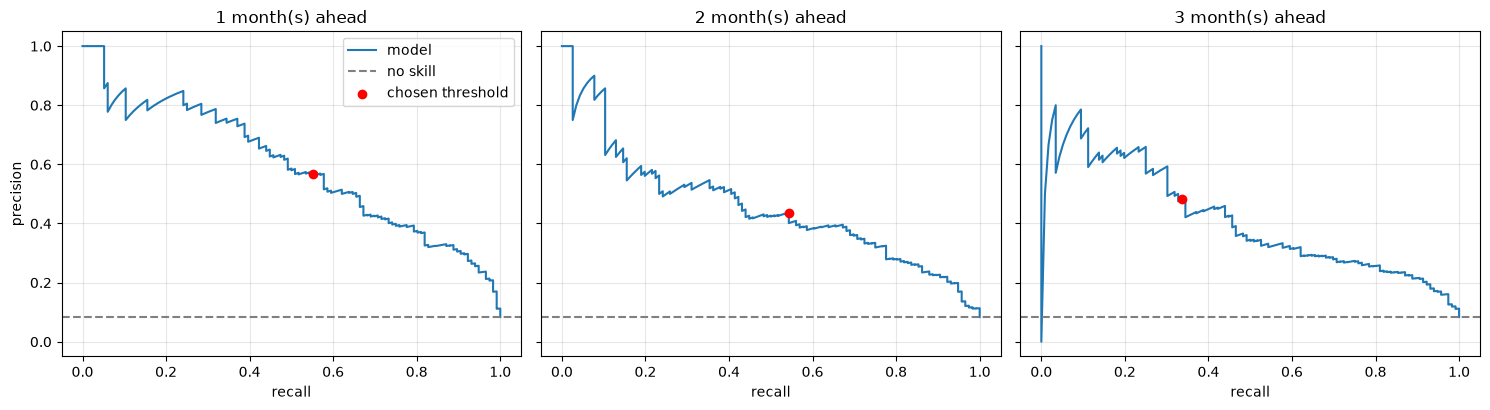

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for a, h in zip(ax, HORIZONS):
    p_, r_, _ = curves[h]
    a.plot(r_, p_, label="model")
    a.axhline(final[h]["te"]["y"].mean(), color="gray", linestyle="--", label="no skill")
    a.scatter([test_table.loc[(h, "gradient boosting (tuned)"), "recall"]],
              [test_table.loc[(h, "gradient boosting (tuned)"), "precision"]], color="red", zorder=3, label="chosen threshold")
    a.set_title(f"{h} month(s) ahead")
    a.set_xlabel("recall")
ax[0].set_ylabel("precision")
ax[0].legend()
plt.tight_layout()
plt.show()

In [23]:
# One month ahead: confusion matrix, calibration and results by product
te = final[1]["te"].copy()
te["p"] = final[1]["p"]
te["warn"] = (te["p"] >= final[1]["threshold"]).astype(int)
cm = pd.crosstab(te["y"].map({0: "no shortage", 1: "shortage"}), te["warn"].map({0: "no warning", 1: "warning"}))
display(cm)

bins = pd.cut(te["p"], [0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0], include_lowest=True)
calib = te.groupby(bins, observed=True).agg(rows=("y", "size"), mean_predicted=("p", "mean"), actual_rate=("y", "mean"))
display(calib.round(3))

by_prod = te.groupby("product").apply(lambda g: pd.Series({
    "rows": len(g), "shortages": int(g["y"].sum()),
    "recall": g.loc[g["y"] == 1, "warn"].mean() if g["y"].sum() else np.nan,
    "PR-AUC": average_precision_score(g["y"], g["p"]) if g["y"].sum() else np.nan}))
display(by_prod.round(2))

warn,no warning,warning
y,,
no shortage,1225,49
shortage,52,64


,rows,mean_predicted,actual_rate
p,,,
"(-0.001, 0.02]",992,0.003,0.008
"(0.02, 0.05]",116,0.032,0.112
"(0.05, 0.1]",75,0.071,0.133
"(0.1, 0.2]",72,0.139,0.222
"(0.2, 0.4]",47,0.293,0.298
"(0.4, 0.7]",48,0.535,0.479
"(0.7, 1.0]",40,0.845,0.800


,rows,shortages,recall,PR-AUC
product,,,,
apples,114.0,8.0,0.75,0.67
avocados,113.0,14.0,0.64,0.63
bananas,116.0,2.0,0.00,0.20
broccoli,114.0,25.0,0.60,0.80
carrots,118.0,1.0,0.00,0.12
grapes,115.0,9.0,0.00,0.19
lettuce,117.0,14.0,0.57,0.61
onions,119.0,0.0,NaN,NaN
oranges,117.0,8.0,0.25,0.66


**Reading the test results**

- The final model beats every baseline at every horizon: test PR-AUC **0.59, 0.46 and 0.41** for 1, 2 and 3 months ahead, against 0.31, 0.22 and 0.12 for persistence (and 0.08 for no skill). ROC-AUC is 0.93, 0.89 and 0.87.
- At the chosen threshold, one month ahead the model raises a warning for about half of the actual shortages (recall 0.55) and about 57% of its warnings are correct (precision 0.57): 64 shortages caught, 52 missed, 49 false alarms among 1,390 test rows.
- Predicted probabilities are reasonable at the high end (rows predicted at 70-100% had an actual shortage rate of 80%) but too low in the 2-10% range (actual rates 11-13%). The test years include the 2021 spike, so the model under-warns when the environment is more stressed than in most of its training data.
- Results differ a lot by product. Strawberries (recall 0.83), apples, broccoli, avocados and lettuce are caught reasonably well, while grapes (0 of 9), oranges and the nearly shortage-free products are not. Per-product numbers rest on very few shortages and should not be over-read.

## Summary

| Question | Finding |
|---|---|
| How much warning can a model give? | Useful at 1 month (PR-AUC 0.59), still clearly better than baselines at 3 months (0.41). Accuracy falls steadily as the horizon grows. |
| Does weather help beyond past availability? | Modestly. Weather matters more at 3 months than at 1 month in the importance analysis, and it clearly helps logistic regression, but adding it to the tree models changed validation accuracy by only a few hundredths. |
| What matters most? | Current availability at 1 month ahead; store and product, inflation-adjusted price, calendar month and weather at 3 months ahead. |

**Limitations.** The data is simulated, so this validates the method rather than describing the real produce market. The test set has only about 115 shortages and covers an unusual stretch (the 2021 spike, then calm years), so results could shift on another period. The tuned settings are a reasonable choice rather than a uniquely best one. The final model is trained by `train.py`, served by `predict.py` and packaged by the `Dockerfile`.